# Tomato Leaf Gate Classification

Binary classifier for the first step of the tomato pipeline.

Goal:

1. Input image -> classify as `tomato_leaf` or `out_of_domain`.
2. If `tomato_leaf`, run the YOLO tomato leaf detector.
3. Crop detected leaf regions.
4. Send crops to the PlantVillage tomato disease classifier.

This notebook is based on the EfficientNet-B0, ResNet50, and Fusion training flow from the tomato disease classification notebook, but uses the prepared `TomatoLeafGate` dataset.


In [1]:
# Install dependencies if your environment does not already have them.
# Kaggle usually has torch/torchvision preinstalled, so this cell may be skipped there.
!pip install -q torch torchvision matplotlib seaborn scikit-learn pillow

## 1. Imports and Seed


In [2]:
import os
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib"))

import random
import json
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models

import warnings
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"PyTorch version : {torch.__version__}")
print(f"GPU available   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU name        : {torch.cuda.get_device_name(0)}")
else:
    print("No GPU found. Training will be slower on CPU.")


PyTorch version : 2.10.0+cu128
GPU available   : True
GPU name        : Tesla T4


## 2. Configuration


In [3]:
# Kaggle path for your uploaded TomatoLeafGate dataset.
KAGGLE_DATA_DIR = Path("/kaggle/input/datasets/vthanhdt/tomato-leaf-gate")
LOCAL_DATA_DIR = Path("TomatoLeafGate")

# Auto-detect dataset root. The selected folder must contain train/val/test.
def has_splits(path):
    return (path / "train").is_dir() and (path / "val").is_dir() and (path / "test").is_dir()


def find_dataset_root():
    if has_splits(KAGGLE_DATA_DIR):
        return KAGGLE_DATA_DIR

    # If Kaggle preserved the local folder name inside the uploaded dataset.
    kaggle_nested = KAGGLE_DATA_DIR / "TomatoLeafGate"
    if has_splits(kaggle_nested):
        return kaggle_nested

    if has_splits(LOCAL_DATA_DIR):
        return LOCAL_DATA_DIR

    raise FileNotFoundError(
        "Could not find TomatoLeafGate train/val/test folders. "
        f"Checked: {KAGGLE_DATA_DIR}, {kaggle_nested}, {LOCAL_DATA_DIR}"
    )

DATA_DIR = find_dataset_root()
OUTPUT_DIR = Path("model_tomato_leaf_gate")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_TO_IDX = {"tomato_leaf": 0, "out_of_domain": 1}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}
classes = [IDX_TO_CLASS[i] for i in range(len(IDX_TO_CLASS))]
num_classes = len(classes)

BATCH_SIZE = 32
NUM_EPOCHS = 20
LR = 1e-3
PATIENCE = 5
IMG_SIZE = 224
DROPOUT = 0.5
NUM_WORKERS = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device      : {DEVICE}")
print(f"Data dir    : {DATA_DIR}")
print(f"Output dir  : {OUTPUT_DIR}")
print(f"Classes     : {CLASS_TO_IDX}")
print(f"Batch size  : {BATCH_SIZE}")
print(f"Max epochs  : {NUM_EPOCHS}")
print(f"LR          : {LR}")
print(f"Patience    : {PATIENCE}")
print(f"Image size  : {IMG_SIZE}x{IMG_SIZE}")


Device      : cuda
Data dir    : /kaggle/input/datasets/vthanhdt/tomato-leaf-gate
Output dir  : model_tomato_leaf_gate
Classes     : {'tomato_leaf': 0, 'out_of_domain': 1}
Batch size  : 32
Max epochs  : 20
LR          : 0.001
Patience    : 5
Image size  : 224x224


## 3. Data Preprocessing


In [4]:
data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.RandomRotation(15),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    "test": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
}
print("Data transforms ready")


Data transforms ready


In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".JPG", ".JPEG", ".PNG"}

class GateDataset(Dataset):
    """ImageFolder-like dataset with fixed class indices."""

    def __init__(self, split_dir, class_to_idx, transform=None):
        self.split_dir = Path(split_dir)
        self.class_to_idx = class_to_idx
        self.transform = transform
        self.samples = []

        for class_name, label in class_to_idx.items():
            class_dir = self.split_dir / class_name
            if not class_dir.is_dir():
                raise FileNotFoundError(f"Missing class folder: {class_dir}")
            for path in sorted(class_dir.iterdir()):
                if path.is_file() and path.suffix in IMAGE_EXTS:
                    self.samples.append((str(path), label))

        if not self.samples:
            raise RuntimeError(f"No images found in: {self.split_dir}")

    def __getitem__(self, index):
        path, label = self.samples[index]
        try:
            image = Image.open(path).convert("RGB")
        except (OSError, UnidentifiedImageError):
            return self.__getitem__((index + 1) % len(self.samples))
        if self.transform:
            image = self.transform(image)
        return image, label

    def __len__(self):
        return len(self.samples)

print("GateDataset ready")


GateDataset ready


In [6]:
train_dataset = GateDataset(DATA_DIR / "train", CLASS_TO_IDX, transform=data_transforms["train"])
val_dataset = GateDataset(DATA_DIR / "val", CLASS_TO_IDX, transform=data_transforms["val"])
test_dataset = GateDataset(DATA_DIR / "test", CLASS_TO_IDX, transform=data_transforms["test"])

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)

print("DataLoaders created")
print(f"Train images : {len(train_dataset)}")
print(f"Val images   : {len(val_dataset)}")
print(f"Test images  : {len(test_dataset)}")


DataLoaders created
Train images : 4800
Val images   : 600
Test images  : 600


## 4. Dataset Check


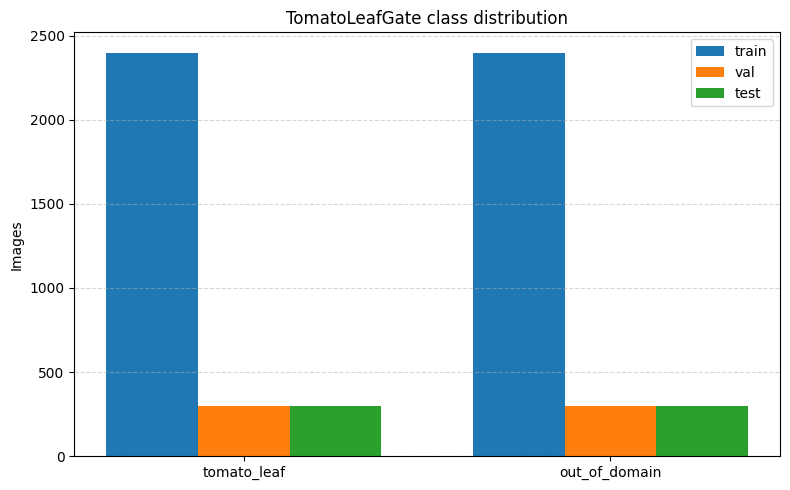

train {'tomato_leaf': 2400, 'out_of_domain': 2400}
val {'tomato_leaf': 300, 'out_of_domain': 300}
test {'tomato_leaf': 300, 'out_of_domain': 300}


In [7]:
def dataset_counter(dataset):
    return Counter(label for _, label in dataset.samples)

split_counters = {
    "train": dataset_counter(train_dataset),
    "val": dataset_counter(val_dataset),
    "test": dataset_counter(test_dataset),
}

x = np.arange(num_classes)
width = 0.25
plt.figure(figsize=(8, 5))
for offset, split in zip([-width, 0, width], ["train", "val", "test"]):
    counts = [split_counters[split].get(i, 0) for i in range(num_classes)]
    plt.bar(x + offset, counts, width, label=split)
plt.xticks(x, classes)
plt.ylabel("Images")
plt.title("TomatoLeafGate class distribution")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

for split, counter in split_counters.items():
    print(split, {IDX_TO_CLASS[k]: v for k, v in counter.items()})


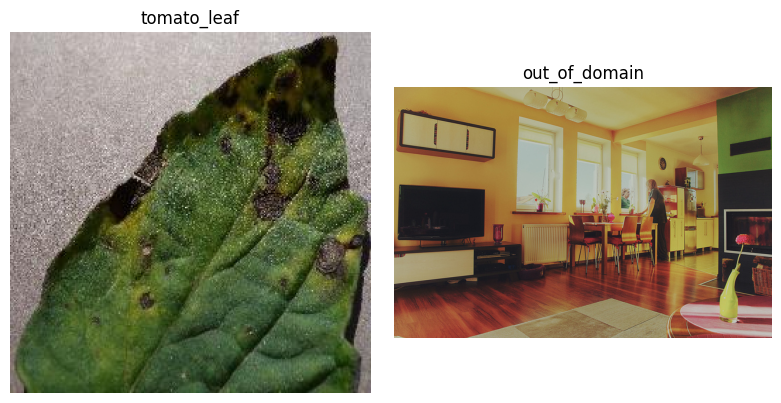

In [8]:
fig, axes = plt.subplots(1, num_classes, figsize=(8, 4))
if num_classes == 1:
    axes = [axes]

for cls_idx, cls_name in enumerate(classes):
    sample_path = next(path for path, label in train_dataset.samples if label == cls_idx)
    img = Image.open(sample_path).convert("RGB")
    axes[cls_idx].imshow(img)
    axes[cls_idx].set_title(cls_name)
    axes[cls_idx].axis("off")

plt.tight_layout()
plt.show()


## 5. Model Definitions


In [9]:
def build_classifier_head(in_features, num_classes, dropout=DROPOUT):
    return nn.Sequential(
        nn.Linear(in_features, 1024),
        nn.BatchNorm1d(1024),
        nn.ReLU(inplace=True),
        nn.Dropout(p=dropout),
        nn.Linear(1024, 256),
        nn.BatchNorm1d(256),
        nn.ReLU(inplace=True),
        nn.Dropout(p=dropout / 2),
        nn.Linear(256, num_classes),
    )


def build_efficientnet(num_classes, dropout=DROPOUT, pretrained=True):
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    for param in model.parameters():
        param.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier = build_classifier_head(in_features, num_classes, dropout)
    return model


def build_resnet50(num_classes, dropout=DROPOUT, pretrained=True):
    weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet50(weights=weights)
    for param in model.parameters():
        param.requires_grad = False
    in_features = model.fc.in_features
    model.fc = build_classifier_head(in_features, num_classes, dropout)
    return model

print("EfficientNet-B0 and ResNet50 builders ready")


EfficientNet-B0 and ResNet50 builders ready


In [11]:
def count_params(model, name):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{name}")
    print(f"  Total params     : {total:,}")
    print(f"  Trainable params : {trainable:,} ({trainable / total * 100:.2f}%)")

_eff = build_efficientnet(num_classes)
_res = build_resnet50(num_classes)
_fusion = FusionModel(num_classes)
count_params(_eff, "EfficientNet-B0")
count_params(_res, "ResNet50")
del _eff, _res, _fusion


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 133MB/s] 


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 201MB/s]


EfficientNet-B0
  Total params     : 5,584,766
  Trainable params : 1,577,218 (28.24%)
ResNet50
  Total params     : 25,871,682
  Trainable params : 2,363,650 (9.14%)
Fusion
  Total params     : 31,189,950
  Trainable params : 3,674,370 (11.78%)


## 6. Training


In [12]:
def train_model(model, train_loader, val_loader, num_epochs=NUM_EPOCHS, patience=PATIENCE):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=3, factor=0.5)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = None
    epochs_no_improve = 0

    for epoch in range(num_epochs):
        model.train()
        t_loss, t_correct, t_total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            t_loss += loss.item() * images.size(0)
            preds = outputs.argmax(1)
            t_correct += preds.eq(labels).sum().item()
            t_total += labels.size(0)

        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                outputs = model(images)
                loss = criterion(outputs, labels)
                v_loss += loss.item() * images.size(0)
                preds = outputs.argmax(1)
                v_correct += preds.eq(labels).sum().item()
                v_total += labels.size(0)

        avg_t_loss = t_loss / t_total
        avg_v_loss = v_loss / v_total
        t_acc = t_correct / t_total * 100
        v_acc = v_correct / v_total * 100

        history["train_loss"].append(avg_t_loss)
        history["val_loss"].append(avg_v_loss)
        history["train_acc"].append(t_acc)
        history["val_acc"].append(v_acc)

        scheduler.step(avg_v_loss)
        print(
            f"Epoch [{epoch + 1:02d}/{num_epochs}] "
            f"Train Loss={avg_t_loss:.4f} Acc={t_acc:.2f}% | "
            f"Val Loss={avg_v_loss:.4f} Acc={v_acc:.2f}%"
        )

        if avg_v_loss < best_val_loss:
            best_val_loss = avg_v_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping after {patience} epochs without val loss improvement.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    print(f"Best Val Loss: {best_val_loss:.4f}")
    return model, history


In [13]:
def plot_history(history, title="Training History"):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(epochs, history["train_loss"], "b-o", markersize=4, label="Train Loss")
    ax1.plot(epochs, history["val_loss"], "r-o", markersize=4, label="Val Loss")
    ax1.set_title(f"{title} - Loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True, linestyle="--", alpha=0.6)

    ax2.plot(epochs, history["train_acc"], "b-o", markersize=4, label="Train Acc")
    ax2.plot(epochs, history["val_acc"], "r-o", markersize=4, label="Val Acc")
    ax2.set_title(f"{title} - Accuracy (%)")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy (%)")
    ax2.legend()
    ax2.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()


Training EfficientNet-B0 gate classifier
Epoch [01/20] Train Loss=0.0453 Acc=98.48% | Val Loss=0.0158 Acc=99.50%
Epoch [02/20] Train Loss=0.0242 Acc=99.06% | Val Loss=0.0198 Acc=99.17%
Epoch [03/20] Train Loss=0.0179 Acc=99.46% | Val Loss=0.0086 Acc=99.83%
Epoch [04/20] Train Loss=0.0150 Acc=99.44% | Val Loss=0.0092 Acc=99.67%
Epoch [05/20] Train Loss=0.0188 Acc=99.38% | Val Loss=0.0087 Acc=99.50%
Epoch [06/20] Train Loss=0.0101 Acc=99.71% | Val Loss=0.0058 Acc=99.67%
Epoch [07/20] Train Loss=0.0127 Acc=99.54% | Val Loss=0.0111 Acc=99.50%
Epoch [08/20] Train Loss=0.0114 Acc=99.60% | Val Loss=0.0170 Acc=99.33%
Epoch [09/20] Train Loss=0.0110 Acc=99.67% | Val Loss=0.0166 Acc=99.50%
Epoch [10/20] Train Loss=0.0100 Acc=99.69% | Val Loss=0.0106 Acc=99.83%
Epoch [11/20] Train Loss=0.0073 Acc=99.77% | Val Loss=0.0092 Acc=99.83%
Early stopping after 5 epochs without val loss improvement.
Best Val Loss: 0.0058
Saved: model_tomato_leaf_gate/efficientnet_tomato_leaf_gate.pth


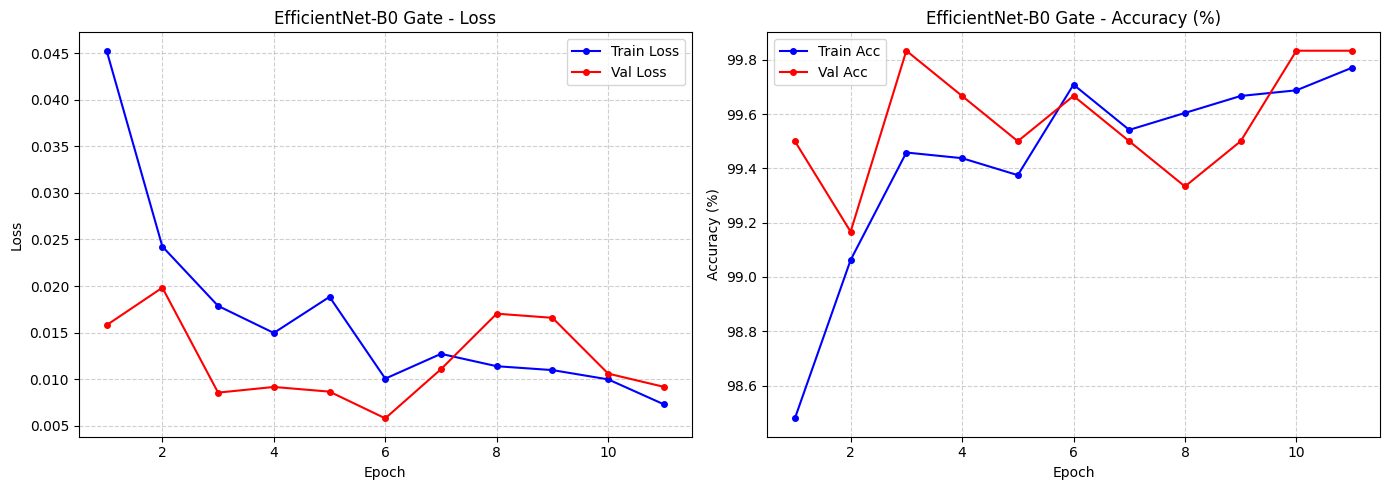

In [14]:
print("Training EfficientNet-B0 gate classifier")
efficientnet = build_efficientnet(num_classes).to(DEVICE)
efficientnet, eff_history = train_model(efficientnet, train_loader, val_loader)
torch.save(efficientnet.state_dict(), OUTPUT_DIR / "efficientnet_tomato_leaf_gate.pth")
print(f"Saved: {OUTPUT_DIR / 'efficientnet_tomato_leaf_gate.pth'}")
plot_history(eff_history, "EfficientNet-B0 Gate")


Training ResNet50 gate classifier
Epoch [01/20] Train Loss=0.0330 Acc=98.85% | Val Loss=0.0085 Acc=99.83%
Epoch [02/20] Train Loss=0.0135 Acc=99.46% | Val Loss=0.0089 Acc=99.67%
Epoch [03/20] Train Loss=0.0125 Acc=99.69% | Val Loss=0.0031 Acc=99.83%
Epoch [04/20] Train Loss=0.0107 Acc=99.62% | Val Loss=0.0024 Acc=100.00%
Epoch [05/20] Train Loss=0.0070 Acc=99.79% | Val Loss=0.0029 Acc=99.83%
Epoch [06/20] Train Loss=0.0121 Acc=99.62% | Val Loss=0.0042 Acc=99.83%
Epoch [07/20] Train Loss=0.0113 Acc=99.69% | Val Loss=0.0042 Acc=99.83%
Epoch [08/20] Train Loss=0.0058 Acc=99.79% | Val Loss=0.0037 Acc=99.83%
Epoch [09/20] Train Loss=0.0059 Acc=99.83% | Val Loss=0.0032 Acc=99.83%
Early stopping after 5 epochs without val loss improvement.
Best Val Loss: 0.0024
Saved: model_tomato_leaf_gate/resnet50_tomato_leaf_gate.pth


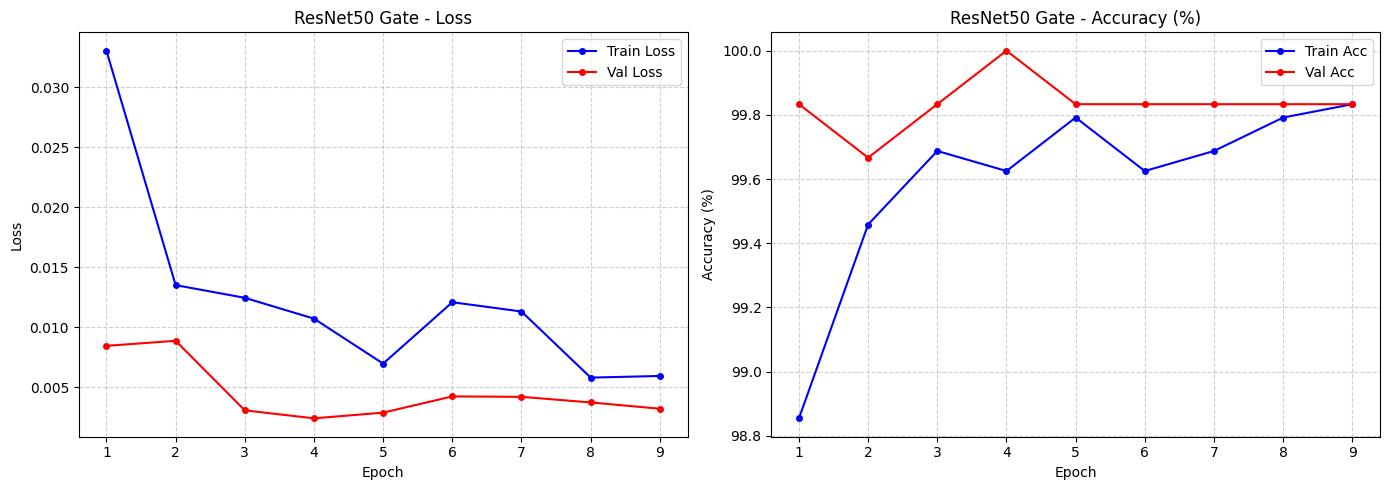

In [15]:
print("Training ResNet50 gate classifier")
resnet50 = build_resnet50(num_classes).to(DEVICE)
resnet50, res_history = train_model(resnet50, train_loader, val_loader)
torch.save(resnet50.state_dict(), OUTPUT_DIR / "resnet50_tomato_leaf_gate.pth")
print(f"Saved: {OUTPUT_DIR / 'resnet50_tomato_leaf_gate.pth'}")
plot_history(res_history, "ResNet50 Gate")


## 7. Evaluation


In [17]:
def evaluate_model(model, test_loader, class_names, title="Model"):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            preds = outputs.argmax(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = sum(p == l for p, l in zip(all_preds, all_labels)) / len(all_labels) * 100
    print(f"\n{title} - Test Accuracy: {acc:.2f}%\n")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - {title}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return acc, all_preds, all_labels



EfficientNet-B0 - Test Accuracy: 99.83%

               precision    recall  f1-score   support

  tomato_leaf       1.00      1.00      1.00       300
out_of_domain       1.00      1.00      1.00       300

     accuracy                           1.00       600
    macro avg       1.00      1.00      1.00       600
 weighted avg       1.00      1.00      1.00       600



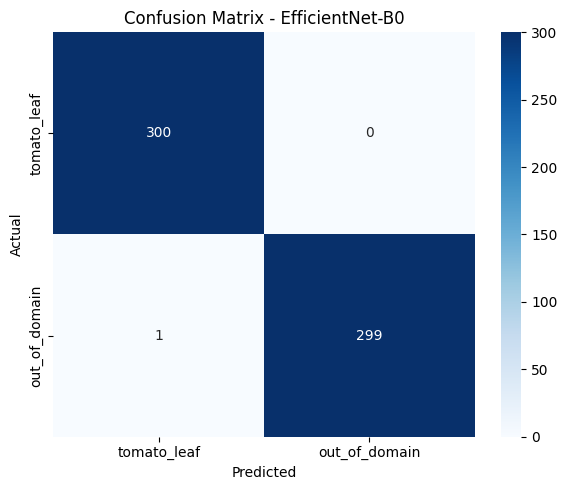


ResNet50 - Test Accuracy: 100.00%

               precision    recall  f1-score   support

  tomato_leaf       1.00      1.00      1.00       300
out_of_domain       1.00      1.00      1.00       300

     accuracy                           1.00       600
    macro avg       1.00      1.00      1.00       600
 weighted avg       1.00      1.00      1.00       600



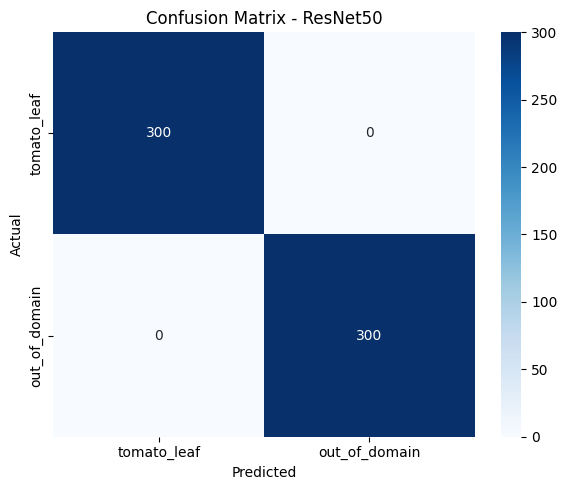

In [18]:
eff_acc, eff_preds, eff_labels = evaluate_model(efficientnet, test_loader, classes, "EfficientNet-B0")
res_acc, res_preds, res_labels = evaluate_model(resnet50, test_loader, classes, "ResNet50")


Final results
EfficientNet-B0   : 99.83%
ResNet50          : 100.00%
Best model: ResNet50 (100.00%)


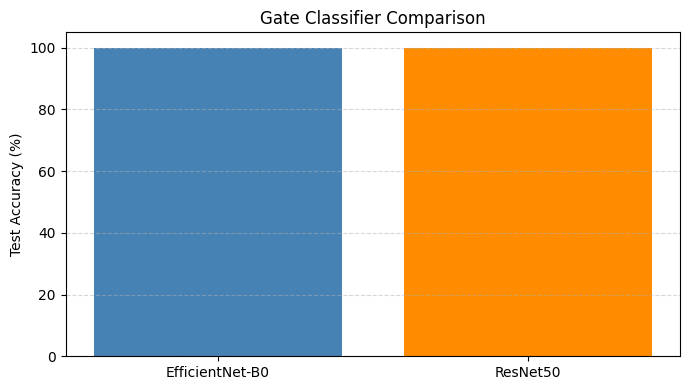

In [19]:
results = {
    "EfficientNet-B0": eff_acc,
    "ResNet50": res_acc,
}

print("Final results")
for name, acc in results.items():
    print(f"{name:<18}: {acc:.2f}%")

best_name = max(results, key=results.get)
print(f"Best model: {best_name} ({results[best_name]:.2f}%)")

with open(OUTPUT_DIR / "class_to_idx.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_TO_IDX, f, indent=2)
with open(OUTPUT_DIR / "results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

plt.figure(figsize=(7, 4))
plt.bar(results.keys(), results.values(), color=["steelblue", "darkorange", "mediumpurple"])
plt.ylim(0, 105)
plt.ylabel("Test Accuracy (%)")
plt.title("Gate Classifier Comparison")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## 8. Single Image Prediction


In [20]:
inference_transform = data_transforms["test"]

def predict_gate_image(model, image_path, threshold=0.5):
    model.eval()
    image = Image.open(image_path).convert("RGB")
    x = inference_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    tomato_prob = float(probs[CLASS_TO_IDX["tomato_leaf"]])
    pred_class = "tomato_leaf" if tomato_prob >= threshold else "out_of_domain"
    return {
        "prediction": pred_class,
        "tomato_leaf_probability": tomato_prob,
        "out_of_domain_probability": float(probs[CLASS_TO_IDX["out_of_domain"]]),
    }

# Example:
# predict_gate_image(efficientnet, "path/to/image.jpg", threshold=0.5)
